In [1]:
import numpy
import skimage as sk
import skimage.io as skio
import os

os.makedirs("out", exist_ok=True)

def save(name, im, signed=False):
    # signed images get 0 mapped to gray
    if signed:
        im = 0.5 + im / (2 * numpy.abs(im).max())
    skio.imsave(f"out/{name}", (numpy.clip(im, 0, 1) * 255).round().astype(numpy.uint8), check_contrast=False)


In [2]:
# part 1.1

def zero_pad(img, kernel):
    # same padding, extra row/col on top/left for even kernels like scipy
    kh, kw = kernel.shape
    top, left = kh // 2, kw // 2
    bottom, right = kh - 1 - top, kw - 1 - left
    padded_img = numpy.zeros((img.shape[0] + top + bottom, img.shape[1] + left + right))
    padded_img[top:top + img.shape[0], left:left + img.shape[1]] = img
    return padded_img

# four for loops
def conv_4loops(img, kernel):
    k = kernel[::-1, ::-1]
    kh, kw = k.shape
    padded = zero_pad(img, kernel)
    out = numpy.zeros(img.shape)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            total = 0.0
            for m in range(kh):
                for n in range(kw):
                    total += k[m, n] * padded[i + m, j + n]
            out[i, j] = total
    return out

# two for loops
def conv_2loops(img, kernel):
    k = kernel[::-1, ::-1]
    kh, kw = k.shape
    padded = zero_pad(img, kernel)
    out = numpy.zeros(img.shape)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            out[i, j] = numpy.sum(padded[i:i + kh, j:j + kw] * k)
    return out

img = skio.imread("images/andrew.png", as_gray=True)

box = numpy.ones((9, 9)) / 81
Dx = numpy.array([[1, -1]])
Dy = numpy.array([[1], [-1]])


box: 4 loops 3.891s, 2 loops 0.464s, scipy 0.0238s, match: True


Dx: 4 loops 0.145s, 2 loops 0.448s, scipy 0.0020s, match: True


Dy: 4 loops 0.158s, 2 loops 0.449s, scipy 0.0025s, match: True


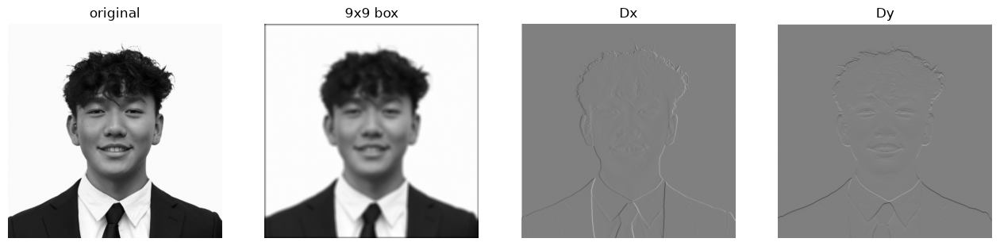

In [3]:
import time
from scipy.signal import convolve2d
import matplotlib.pyplot as plt

results = {}
for name, kernel in [("box", box), ("Dx", Dx), ("Dy", Dy)]:
    t = time.perf_counter(); r4 = conv_4loops(img, kernel); t4 = time.perf_counter() - t
    t = time.perf_counter(); r2 = conv_2loops(img, kernel); t2 = time.perf_counter() - t
    t = time.perf_counter(); rs = convolve2d(img, kernel, mode="same", boundary="fill", fillvalue=0); ts = time.perf_counter() - t
    print(f"{name}: 4 loops {t4:.3f}s, 2 loops {t2:.3f}s, scipy {ts:.4f}s, match: {numpy.allclose(r4, rs) and numpy.allclose(r2, rs)}")
    results[name] = r2

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("original")
axes[1].imshow(results["box"], cmap="gray"); axes[1].set_title("9x9 box")
for ax, name in zip(axes[2:], ["Dx", "Dy"]):
    a = numpy.abs(results[name]).max()
    ax.imshow(results[name], cmap="gray", vmin=-a, vmax=a); ax.set_title(name)
for ax in axes: ax.axis("off")
plt.show()

save("1_1_original.png", img)
save("1_1_box.png", results["box"])
save("1_1_dx.png", results["Dx"], signed=True)
save("1_1_dy.png", results["Dy"], signed=True)

box_symm = convolve2d(img, box, mode="same", boundary="symm")
save("1_1_corner_zero.png", results["box"][:40, :40])
save("1_1_corner_symm.png", box_symm[:40, :40])


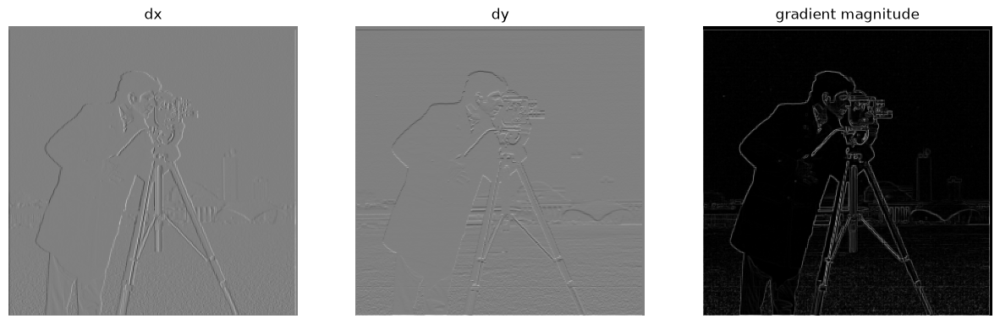

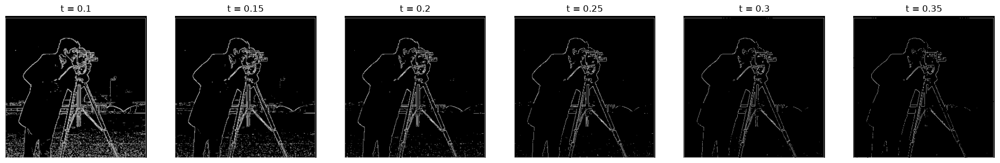

In [4]:
# part 1.2

cam = skio.imread("images/cameraman.png", as_gray=True)

dx = convolve2d(cam, Dx, mode="same", boundary="symm")
dy = convolve2d(cam, Dy, mode="same", boundary="symm")
mag = numpy.sqrt(dx ** 2 + dy ** 2)
t = 0.25
edges = mag > t

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, title in zip(axes, [dx, dy], ["dx", "dy"]):
    a = numpy.abs(im).max()
    ax.imshow(im, cmap="gray", vmin=-a, vmax=a); ax.set_title(title)
axes[2].imshow(mag, cmap="gray"); axes[2].set_title("gradient magnitude")
for ax in axes: ax.axis("off")
plt.show()

thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35]
fig, axes = plt.subplots(1, len(thresholds), figsize=(4 * len(thresholds), 4))
for ax, th in zip(axes, thresholds):
    ax.imshow(mag > th, cmap="gray"); ax.set_title(f"t = {th}"); ax.axis("off")
plt.savefig("out/1_2_threshold_sweep.png", bbox_inches="tight")
plt.show()

save("1_2_dx.png", dx, signed=True)
save("1_2_dy.png", dy, signed=True)
save("1_2_mag.png", mag / mag.max())
save("1_2_edges.png", edges.astype(float))


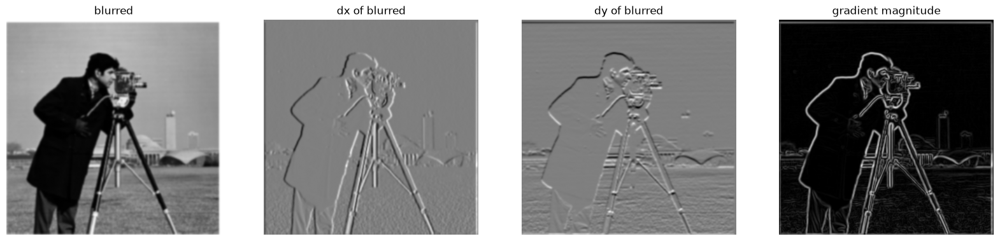

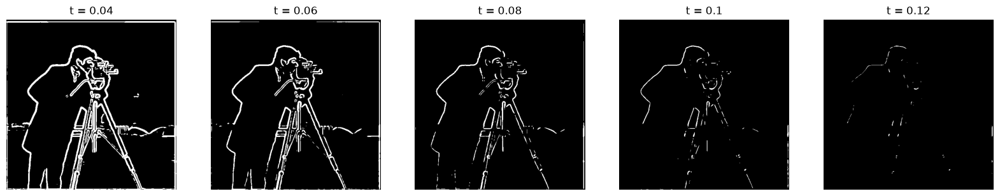

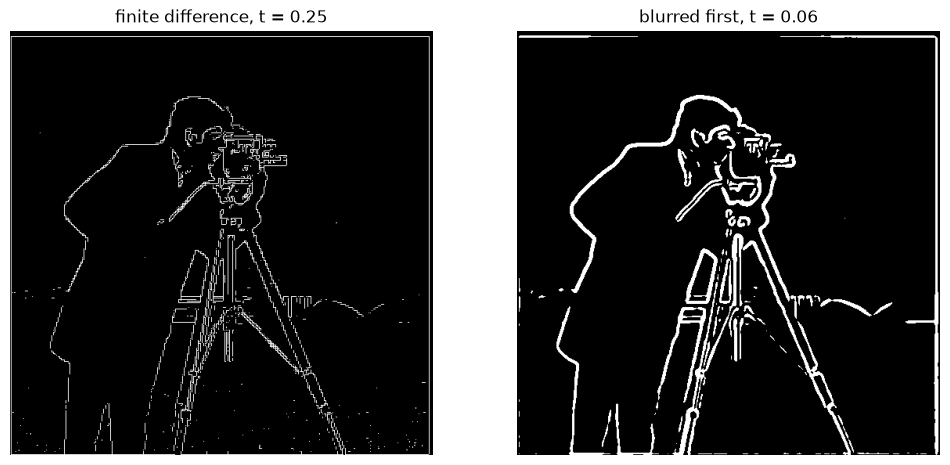

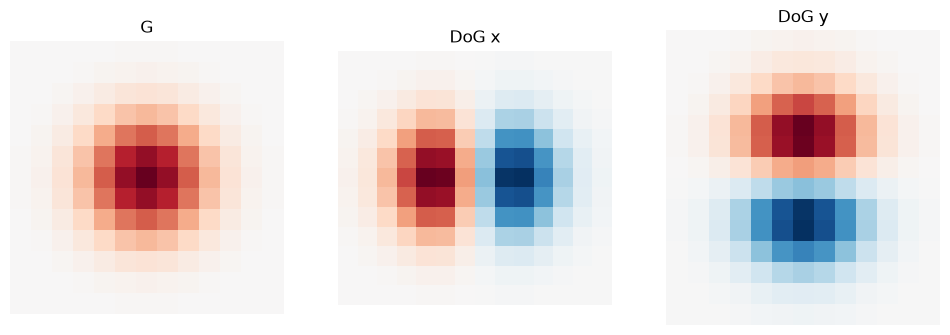

max difference in dx: 9.514958265732787e-16
max difference in dy: 8.344019919448442e-16
same edge pixels: True


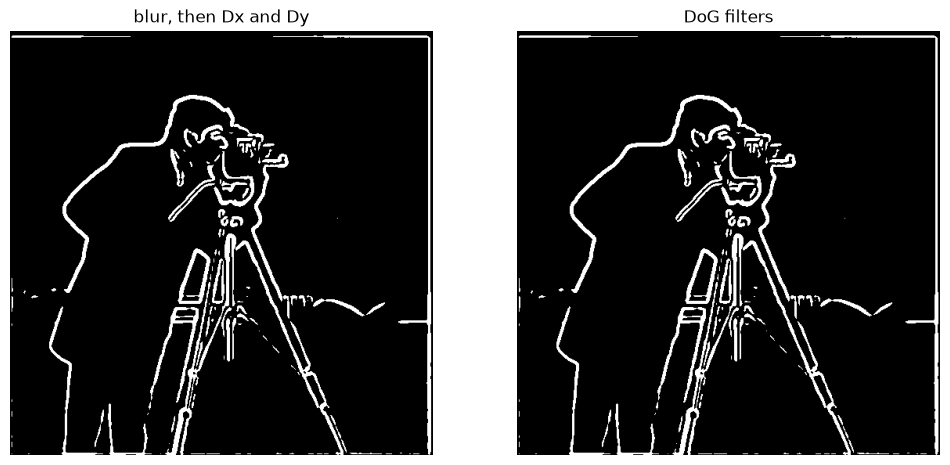

In [5]:
# part 1.3
import cv2

g = cv2.getGaussianKernel(13, 2)
G = g @ g.T

# blur first, then difference
blur = convolve2d(cam, G, mode="same", boundary="symm")
bdx = convolve2d(blur, Dx, mode="same", boundary="symm")
bdy = convolve2d(blur, Dy, mode="same", boundary="symm")
bmag = numpy.sqrt(bdx ** 2 + bdy ** 2)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(blur, cmap="gray"); axes[0].set_title("blurred")
for ax, im, title in zip(axes[1:3], [bdx, bdy], ["dx of blurred", "dy of blurred"]):
    a = numpy.abs(im).max()
    ax.imshow(im, cmap="gray", vmin=-a, vmax=a); ax.set_title(title)
axes[3].imshow(bmag, cmap="gray"); axes[3].set_title("gradient magnitude")
for ax in axes: ax.axis("off")
plt.show()

thresholds = [0.04, 0.06, 0.08, 0.1, 0.12]
fig, axes = plt.subplots(1, len(thresholds), figsize=(4 * len(thresholds), 4))
for ax, th in zip(axes, thresholds):
    ax.imshow(bmag > th, cmap="gray"); ax.set_title(f"t = {th}"); ax.axis("off")
plt.savefig("out/1_3_threshold_sweep.png", bbox_inches="tight")
plt.show()

t_blur = 0.06
bedges = bmag > t_blur

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(edges, cmap="gray"); axes[0].set_title(f"finite difference, t = {t}")
axes[1].imshow(bedges, cmap="gray"); axes[1].set_title(f"blurred first, t = {t_blur}")
for ax in axes: ax.axis("off")
plt.show()

# single convolution with derivative of gaussian filters
DoGx = convolve2d(G, Dx)
DoGy = convolve2d(G, Dy)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, k, title in zip(axes, [G, DoGx, DoGy], ["G", "DoG x", "DoG y"]):
    a = numpy.abs(k).max()
    ax.imshow(k, cmap="RdBu_r", vmin=-a, vmax=a); ax.set_title(title); ax.axis("off")
plt.savefig("out/1_3_filters.png", bbox_inches="tight")
plt.show()

ddx = convolve2d(cam, DoGx, mode="same", boundary="symm")
ddy = convolve2d(cam, DoGy, mode="same", boundary="symm")
dmag = numpy.sqrt(ddx ** 2 + ddy ** 2)
dedges = dmag > t_blur

m = 10  # skip the border, where mirroring before vs after the blur differs
print("max difference in dx:", numpy.abs(bdx - ddx)[m:-m, m:-m].max())
print("max difference in dy:", numpy.abs(bdy - ddy)[m:-m, m:-m].max())
print("same edge pixels:", numpy.array_equal(bedges[m:-m, m:-m], dedges[m:-m, m:-m]))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(bedges, cmap="gray"); axes[0].set_title("blur, then Dx and Dy")
axes[1].imshow(dedges, cmap="gray"); axes[1].set_title("DoG filters")
for ax in axes: ax.axis("off")
plt.show()

save("1_3_blur.png", blur)
save("1_3_dx.png", bdx, signed=True)
save("1_3_dy.png", bdy, signed=True)
save("1_3_mag.png", bmag / bmag.max())
save("1_3_edges.png", bedges.astype(float))
save("1_3_dog_edges.png", dedges.astype(float))


cv2 vs convolve2d: 2.4202861936828413e-14
two steps vs one unsharp convolution: 2.4147350785597155e-14


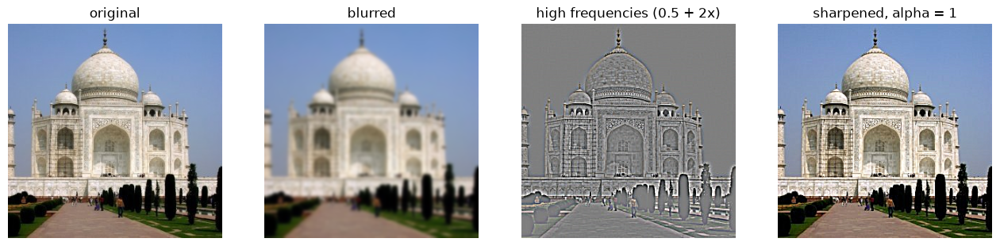

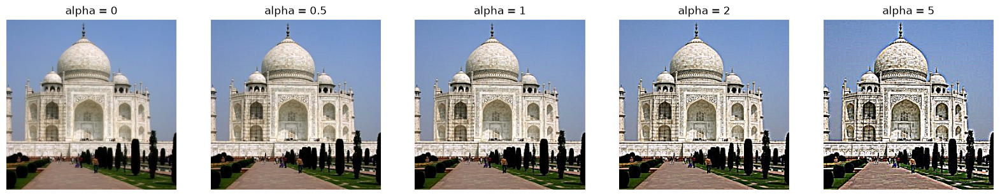

In [6]:
# part 2.1
from skimage.color import rgb2gray

def show(ims, titles, size=4):
    fig, axes = plt.subplots(1, len(ims), figsize=(size * len(ims), size))
    for ax, im, title in zip(numpy.atleast_1d(axes), ims, titles):
        ax.imshow(numpy.clip(im, 0, 1), cmap="gray", vmin=0, vmax=1)
        ax.set_title(title); ax.axis("off")
    plt.show()

def blur(im, sigma):
    g = cv2.getGaussianKernel(2 * int(numpy.ceil(3 * sigma)) + 1, sigma)
    return cv2.sepFilter2D(im, -1, g, g, borderType=cv2.BORDER_REFLECT)

def unsharp_kernel(sigma, alpha):
    ksize = 2 * int(numpy.ceil(3 * sigma)) + 1
    g = cv2.getGaussianKernel(ksize, sigma)
    impulse = numpy.zeros((ksize, ksize))
    impulse[ksize // 2, ksize // 2] = 1
    return (1 + alpha) * impulse - alpha * (g @ g.T)

def filt(im, kernel):
    # filter2D doesn't flip the kernel
    return cv2.filter2D(im, -1, kernel[::-1, ::-1], borderType=cv2.BORDER_REFLECT)

taj = sk.img_as_float(skio.imread("images/taj.jpg"))

k = unsharp_kernel(2, 1)
check = numpy.dstack([convolve2d(taj[..., c], k, mode="same", boundary="symm") for c in range(3)])
print("cv2 vs convolve2d:", numpy.abs(filt(taj, k) - check).max())

low = blur(taj, 2)
high = taj - low
two_step = taj + 1 * high
one_conv = filt(taj, unsharp_kernel(2, 1))
print("two steps vs one unsharp convolution:", numpy.abs(two_step - one_conv).max())

show([taj, low, 0.5 + 2 * high, one_conv], ["original", "blurred", "high frequencies (0.5 + 2x)", "sharpened, alpha = 1"])
save("2_1_taj_blur.png", low)
save("2_1_taj_high.png", 0.5 + 2 * high)

alphas = [0, 0.5, 1, 2, 5]
sharpened = [filt(taj, unsharp_kernel(2, a)) for a in alphas]
show(sharpened, [f"alpha = {a}" for a in alphas])
for a, im in zip(alphas, sharpened):
    save(f"2_1_taj_alpha{a}.png", im)


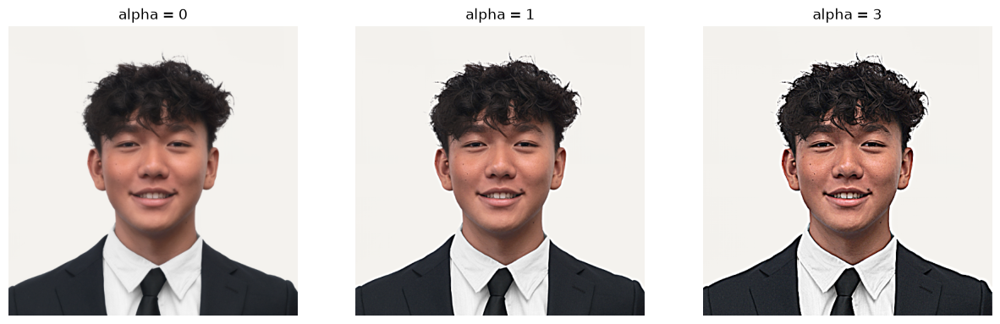

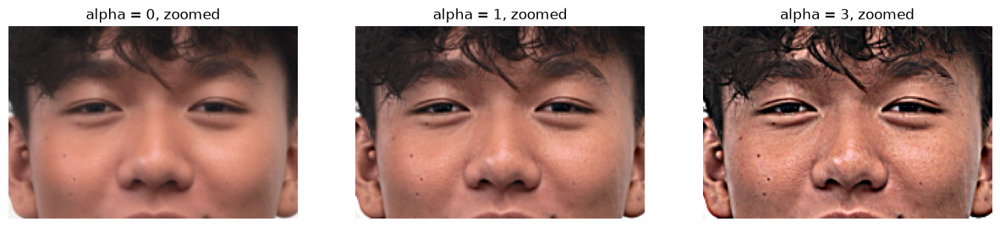

In [7]:
me = sk.img_as_float(skio.imread("images/andrew.png"))

alphas = [0, 1, 3]
sharpened = [filt(me, unsharp_kernel(2, a)) for a in alphas]
show(sharpened, [f"alpha = {a}" for a in alphas], size=5)
show([im[150:290, 150:360] for im in sharpened], [f"alpha = {a}, zoomed" for a in alphas], size=5)
for a, im in zip(alphas, sharpened):
    save(f"2_1_andrew_alpha{a}.png", im)


blurred: 34.35 dB


resharpened, alpha = 0.5: 34.87 dB
resharpened, alpha = 1: 35.30 dB
resharpened, alpha = 2: 35.74 dB
resharpened, alpha = 4: 34.70 dB


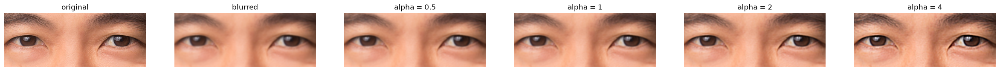

In [8]:
# blur a sharp image, then try to sharpen it back
def psnr(a, b):
    return 10 * numpy.log10(1 / numpy.mean((a - b) ** 2))

ng = sk.img_as_float(skio.imread("images/ng.jpg"))
ng_blur = blur(ng, 3)
print(f"blurred: {psnr(ng, ng_blur):.2f} dB")

alphas = [0.5, 1, 2, 4]
resharpened = [numpy.clip(ng_blur + a * (ng_blur - blur(ng_blur, 3)), 0, 1) for a in alphas]
for a, im in zip(alphas, resharpened):
    print(f"resharpened, alpha = {a}: {psnr(ng, im):.2f} dB")

eye = (slice(983, 1263), slice(491, 1228))
show([ng[eye], ng_blur[eye]] + [im[eye] for im in resharpened],
     ["original", "blurred"] + [f"alpha = {a}" for a in alphas], size=5)
save("2_1_ng_eye_original.png", ng[eye])
save("2_1_ng_eye_blur.png", ng_blur[eye])
for a, im in zip(alphas, resharpened):
    save(f"2_1_ng_eye_alpha{a}.png", im[eye])


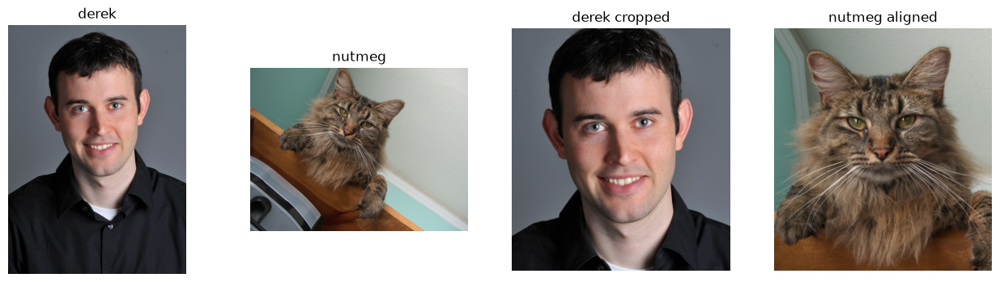

In [9]:
# part 2.2
import skimage.transform as sktr

# (x, y) of the left and right eye
eyes = {
    "derek": [(298, 340), (437, 329)],
    "nutmeg": [(600, 295), (745, 366)],
    "andrew": [(210, 209), (303, 209)],
    "dwight": [(1170, 388), (1350, 393)],
    "efros": [(640, 919), (1044, 916)],
    "ng": [(618, 1123), (1095, 1123)],
}

def align(src, src_eyes, dst, dst_eyes):
    # warp src so its eyes land on dst's eyes, in dst's frame
    tf = sktr.SimilarityTransform.from_estimate(numpy.array(dst_eyes, float), numpy.array(src_eyes, float))
    return sktr.warp(src, tf, output_shape=dst.shape[:2], mode="edge")

def hybrid(im_low, im_high, s_low, s_high):
    low = blur(im_low, s_low)
    high = im_high - blur(im_high, s_high)
    return low, high, numpy.clip(low + high, 0, 1)

def cutoff(sigma):
    # frequency where the gaussian's response drops to half, in cycles per pixel
    return numpy.sqrt(2 * numpy.log(2)) / (2 * numpy.pi * sigma)

def log_fft(im):
    return numpy.log(numpy.abs(numpy.fft.fftshift(numpy.fft.fft2(im))) + 1e-8)

def show_sizes(im, name=None):
    # the same image at 1, 1/2, 1/4, 1/8 size, to fake viewing it from further away
    fig, axes = plt.subplots(1, 4, figsize=(16, 5), gridspec_kw={"width_ratios": [8, 4, 2, 1]})
    for ax, f in zip(axes, [1, 0.5, 0.25, 0.125]):
        small = sktr.rescale(im, f, channel_axis=2 if im.ndim == 3 else None, anti_aliasing=True)
        ax.imshow(numpy.clip(small, 0, 1), cmap="gray", vmin=0, vmax=1); ax.axis("off")
    if name:
        plt.savefig(f"out/{name}", bbox_inches="tight")
    plt.show()

derek = sk.img_as_float(skio.imread("images/DerekPicture.jpg"))
nutmeg = sk.img_as_float(skio.imread("images/nutmeg.jpg"))
nutmeg_aligned = align(nutmeg, eyes["nutmeg"], derek, eyes["derek"])

face = (slice(60, 760), slice(60, 690))
d, n = derek[face], nutmeg_aligned[face]
show([derek, nutmeg, d, n], ["derek", "nutmeg", "derek cropped", "nutmeg aligned"])
save("2_2_derek.png", d)
save("2_2_nutmeg_aligned.png", n)


low pass: sigma 10, cutoff 0.0187 cycles/pixel (period 53 px)
high pass: sigma 6, cutoff 0.0312 cycles/pixel (period 32 px)


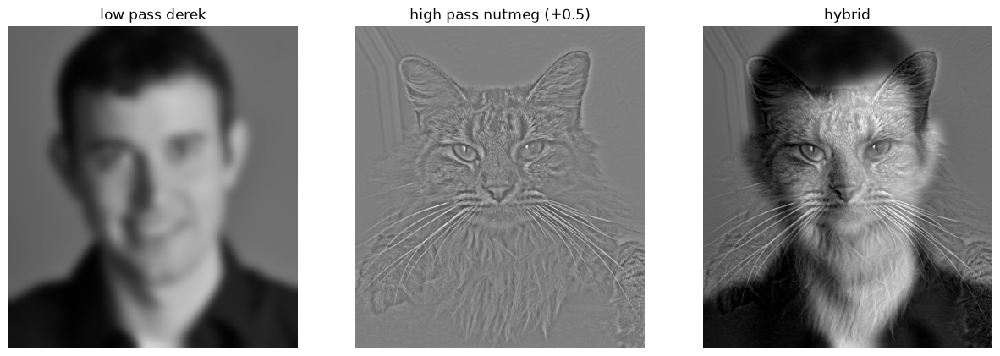

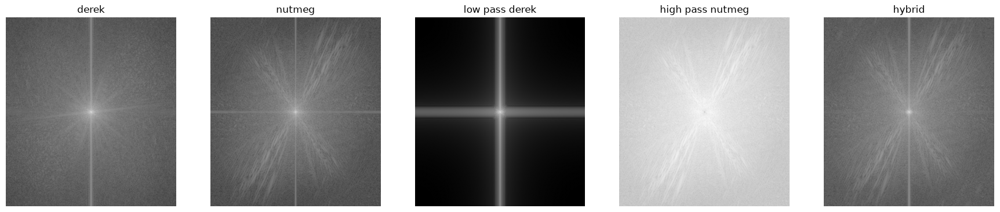

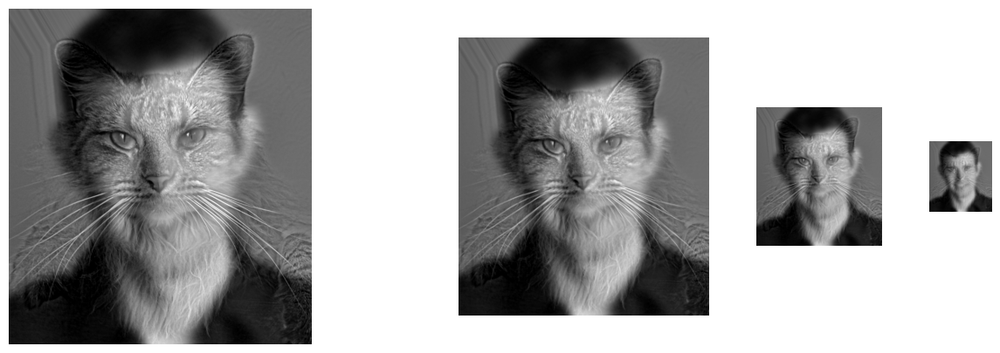

In [10]:
s_low, s_high = 10, 6
print(f"low pass: sigma {s_low}, cutoff {cutoff(s_low):.4f} cycles/pixel (period {1 / cutoff(s_low):.0f} px)")
print(f"high pass: sigma {s_high}, cutoff {cutoff(s_high):.4f} cycles/pixel (period {1 / cutoff(s_high):.0f} px)")

dg, ng_ = rgb2gray(d), rgb2gray(n)
low, high, hyb = hybrid(dg, ng_, s_low, s_high)
show([low, 0.5 + high, hyb], ["low pass derek", "high pass nutmeg (+0.5)", "hybrid"], size=5)
save("2_2_derek_low.png", low)
save("2_2_nutmeg_high.png", 0.5 + high)
save("2_2_derek_nutmeg.png", hyb)

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, im, title in zip(axes, [dg, ng_, low, high, hyb], ["derek", "nutmeg", "low pass derek", "high pass nutmeg", "hybrid"]):
    ax.imshow(log_fft(im), cmap="gray"); ax.set_title(title); ax.axis("off")
plt.savefig("out/2_2_fft.png", bbox_inches="tight")
plt.show()

show_sizes(hyb, "2_2_derek_nutmeg_sizes.png")


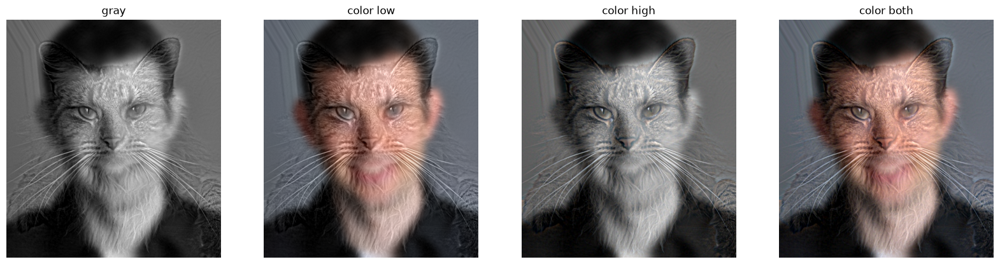

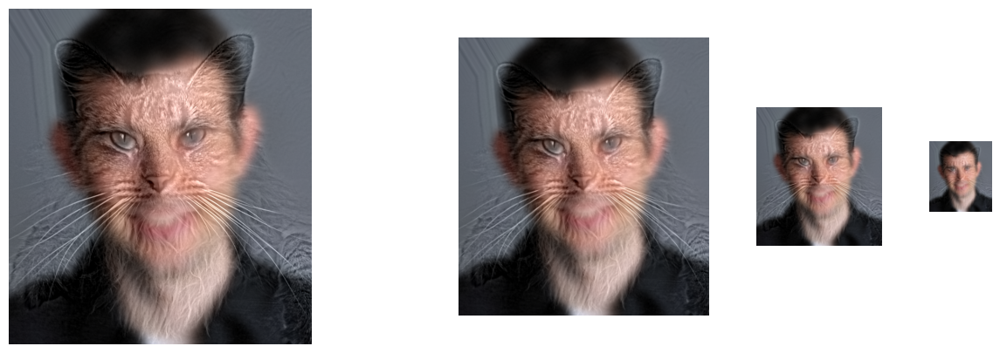

In [11]:
# color in the low part, the high part, or both
def gray3(im):
    return numpy.dstack([rgb2gray(im)] * 3)

variants = {
    "gray": hybrid(gray3(d), gray3(n), s_low, s_high)[2],
    "color low": hybrid(d, gray3(n), s_low, s_high)[2],
    "color high": hybrid(gray3(d), n, s_low, s_high)[2],
    "color both": hybrid(d, n, s_low, s_high)[2],
}
show(list(variants.values()), list(variants.keys()), size=5)
for name, im in variants.items():
    save(f"2_2_color_{name.replace(' ', '_')}.png", im)
show_sizes(variants["color low"])


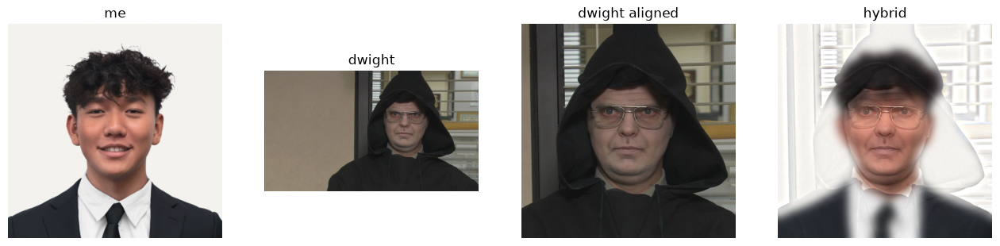

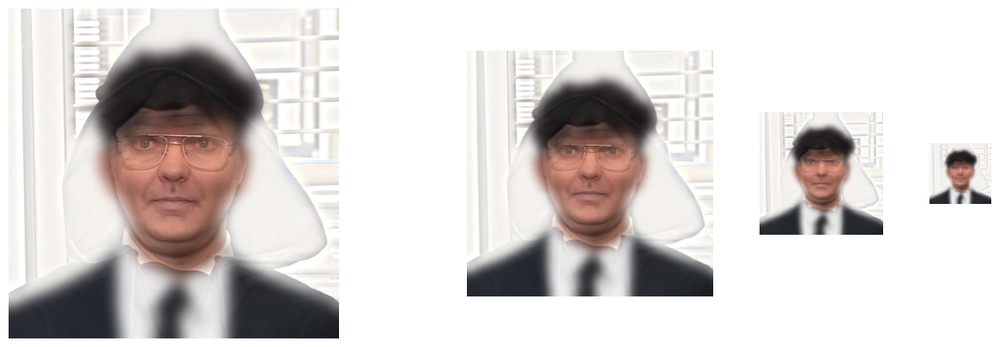

In [12]:
# me far away, dwight up close
dwight = sk.img_as_float(skio.imread("images/dwight.png"))
dwight_aligned = align(dwight, eyes["dwight"], me, eyes["andrew"])

_, _, me_dwight = hybrid(me, dwight_aligned, 10, 8)
show([me, dwight, dwight_aligned, me_dwight], ["me", "dwight", "dwight aligned", "hybrid"])
save("2_2_dwight_aligned.png", dwight_aligned)
save("2_2_me_dwight.png", me_dwight)
show_sizes(me_dwight, "2_2_me_dwight_sizes.png")


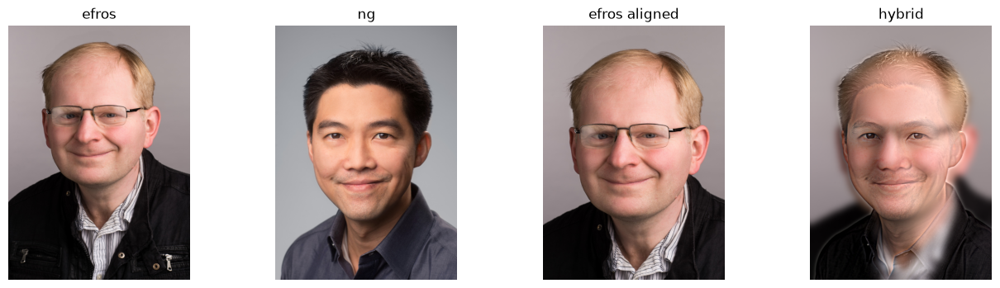

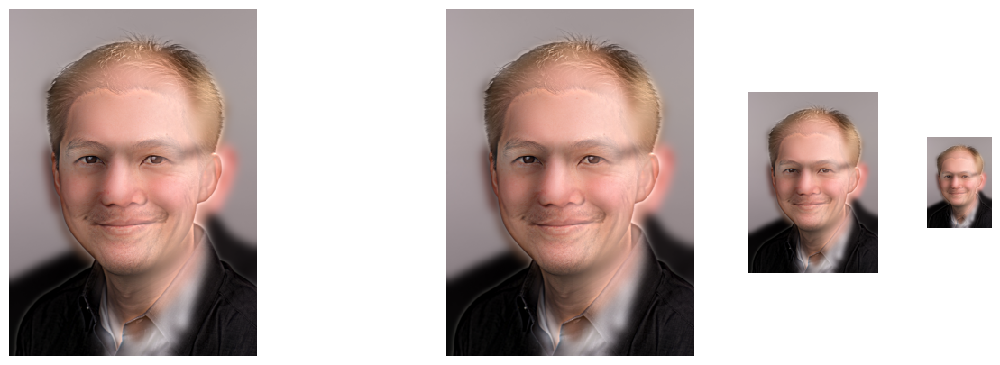

In [13]:
# efros far away, ng up close
efros = sk.img_as_float(skio.imread("images/efros.jpg"))
# ng's photo doesn't reach the bottom of efros's frame, so warp efros into ng's instead
efros_aligned = align(efros, eyes["efros"], ng, eyes["ng"])

_, _, efros_ng = hybrid(efros_aligned, ng, 35, 18)
show([efros, ng, efros_aligned, efros_ng], ["efros", "ng", "efros aligned", "hybrid"])
save("2_2_efros_aligned.png", efros_aligned)
save("2_2_efros_ng.png", efros_ng)
show_sizes(efros_ng, "2_2_efros_ng_sizes.png")


apple: largest error after adding the laplacian stack back up: 1.1e-16


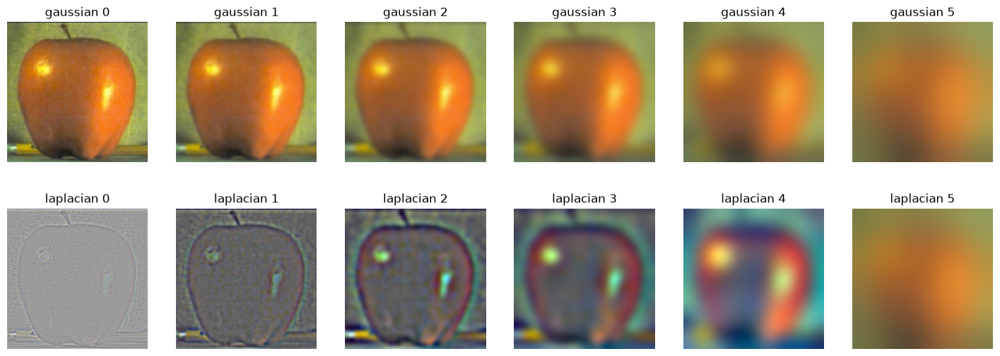

orange: largest error after adding the laplacian stack back up: 1.1e-16


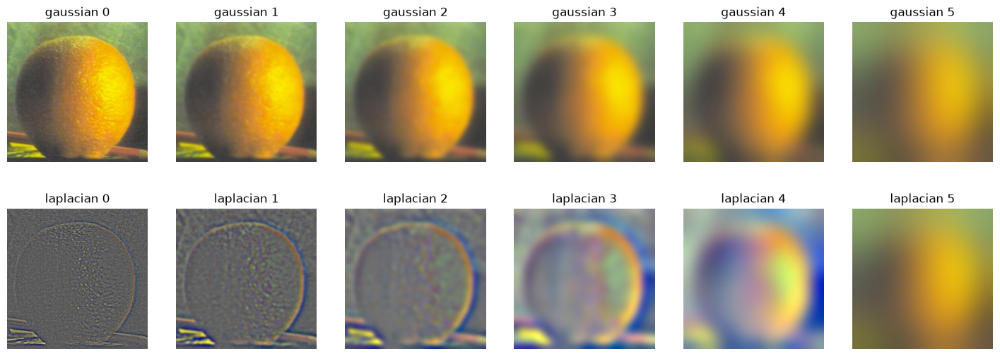

In [14]:
# part 2.3
def gaussian_stack(im, levels, sigma0):
    stack = [im]
    for i in range(1, levels):
        stack.append(blur(stack[-1], sigma0 * 2 ** (i - 1)))
    return stack

def laplacian_stack(im, levels, sigma0):
    g = gaussian_stack(im, levels, sigma0)
    return [g[i] - g[i + 1] for i in range(levels - 1)] + [g[-1]]

def stretch(x):
    return (x - x.min()) / (x.max() - x.min())

apple = sk.img_as_float(skio.imread("images/apple.jpeg"))
orange = sk.img_as_float(skio.imread("images/orange.jpeg"))
levels, sigma0 = 6, 2

for name, im in [("apple", apple), ("orange", orange)]:
    g = gaussian_stack(im, levels, sigma0)
    l = laplacian_stack(im, levels, sigma0)
    print(f"{name}: largest error after adding the laplacian stack back up: {numpy.abs(sum(l) - im).max():.1e}")
    fig, axes = plt.subplots(2, levels, figsize=(3 * levels, 6.3))
    for i in range(levels):
        axes[0, i].imshow(numpy.clip(g[i], 0, 1)); axes[0, i].set_title(f"gaussian {i}")
        axes[1, i].imshow(stretch(l[i]) if i < levels - 1 else numpy.clip(l[i], 0, 1)); axes[1, i].set_title(f"laplacian {i}")
    for ax in axes.ravel(): ax.axis("off")
    plt.savefig(f"out/2_3_{name}_stacks.png", bbox_inches="tight")
    plt.show()


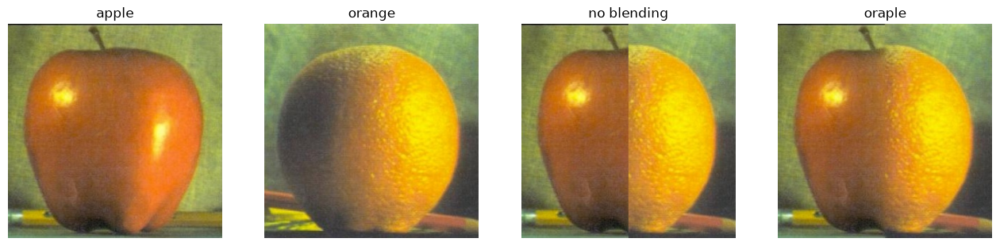

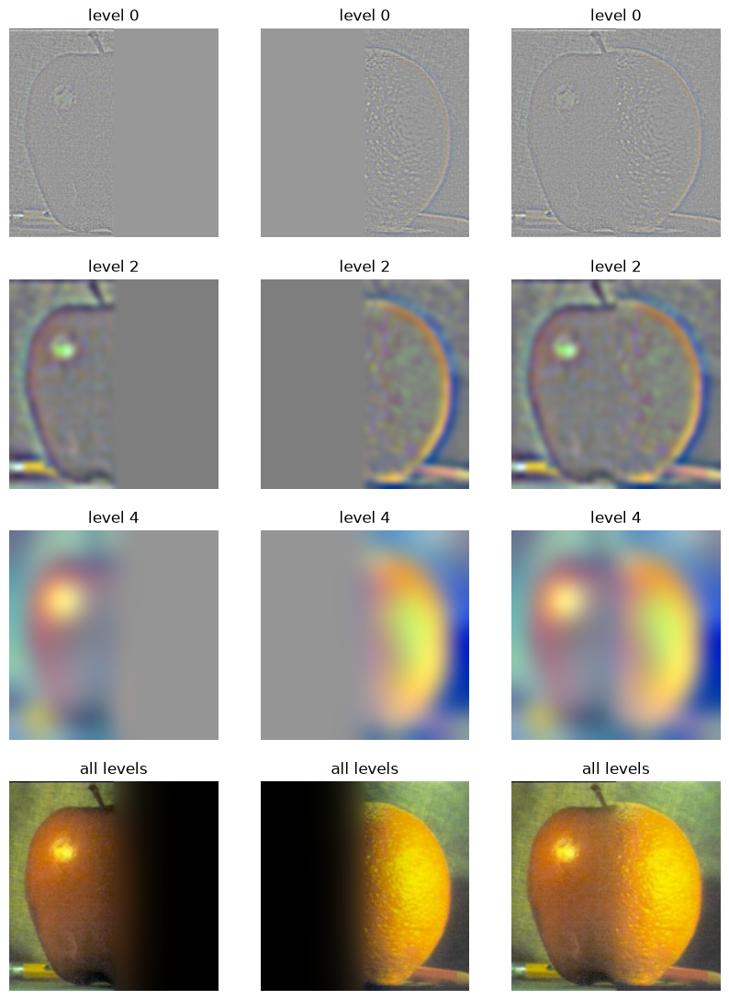

In [15]:
# part 2.4
def blend(a, b, mask, levels, sigma0):
    la = laplacian_stack(a, levels, sigma0)
    lb = laplacian_stack(b, levels, sigma0)
    gm = [m[..., None] for m in gaussian_stack(mask, levels, sigma0)]
    parts = [(m * x, (1 - m) * y) for m, x, y in zip(gm, la, lb)]
    return numpy.clip(sum(x + y for x, y in parts), 0, 1), parts

def show_bands(parts, rows, name):
    # recreates szeliski fig 3.42, each row is one laplacian level, the bottom row adds every level up
    fig, axes = plt.subplots(len(rows) + 1, 3, figsize=(10, 3.4 * (len(rows) + 1)))
    for r, i in enumerate(rows):
        x, y = parts[i]
        trio = [x, y, x + y]
        lo, hi = min(t.min() for t in trio), max(t.max() for t in trio)
        for c, t in enumerate(trio):
            axes[r, c].imshow((t - lo) / (hi - lo)); axes[r, c].set_title(f"level {i}")
    total_a = sum(x for x, _ in parts)
    total_b = sum(y for _, y in parts)
    for c, t in enumerate([total_a, total_b, total_a + total_b]):
        axes[-1, c].imshow(numpy.clip(t, 0, 1)); axes[-1, c].set_title("all levels")
    for ax in axes.ravel(): ax.axis("off")
    plt.savefig(f"out/{name}", bbox_inches="tight")
    plt.show()

h, w = apple.shape[:2]
step = numpy.zeros((h, w))
step[:, :w // 2] = 1
oraple, parts = blend(apple, orange, step, levels, sigma0)
naive = step[..., None] * apple + (1 - step[..., None]) * orange
show([apple, orange, naive, oraple], ["apple", "orange", "no blending", "oraple"])
save("2_4_oraple.png", oraple)
save("2_4_oraple_naive.png", naive)
show_bands(parts, [0, 2, 4], "2_4_oraple_bands.png")


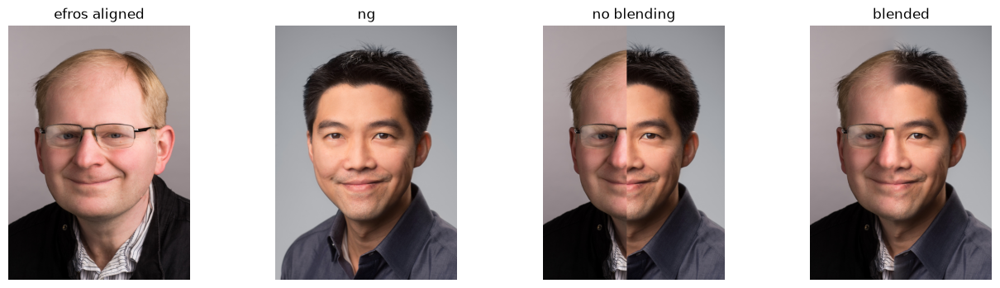

In [16]:
# half efros, half ng
h, w = ng.shape[:2]
seam = (eyes["ng"][0][0] + eyes["ng"][1][0]) // 2
half = numpy.zeros((h, w))
half[:, :seam] = 1
efros_ng_blend, _ = blend(efros_aligned, ng, half, 7, 3)
naive = half[..., None] * efros_aligned + (1 - half[..., None]) * ng
show([efros_aligned, ng, naive, efros_ng_blend], ["efros aligned", "ng", "no blending", "blended"])
save("2_4_efros_ng.png", efros_ng_blend)
save("2_4_efros_ng_naive.png", naive)


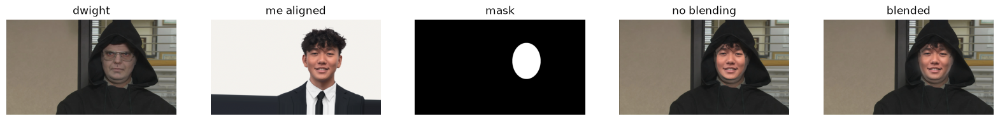

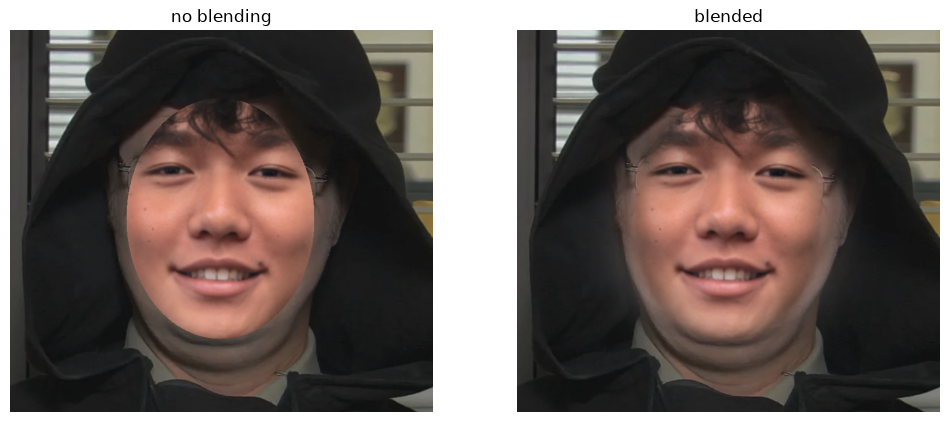

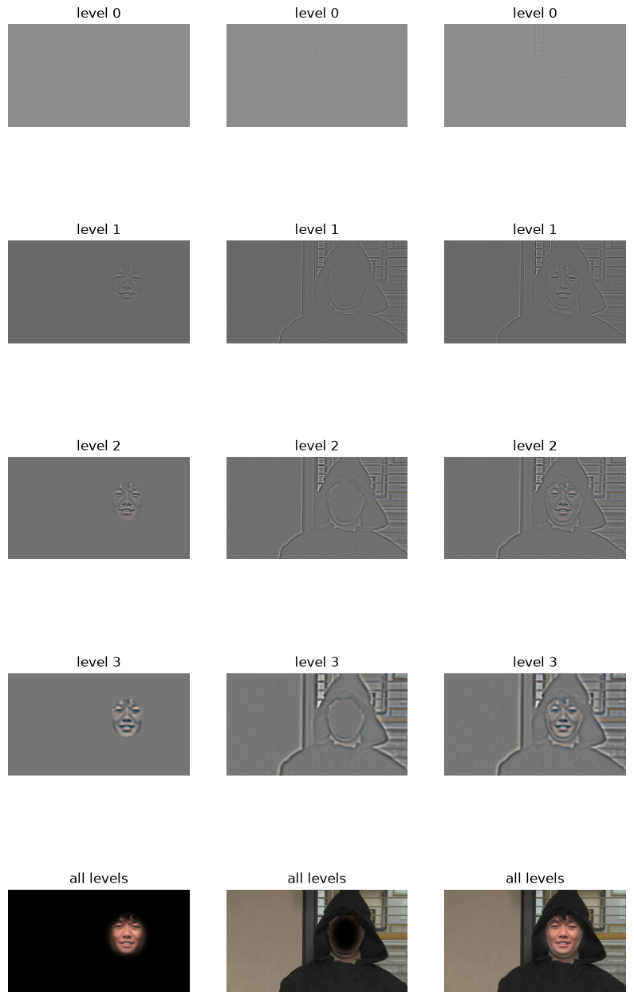

In [17]:
# my face in dwight's hood
me_aligned = align(me, eyes["andrew"], dwight, eyes["dwight"])

def ellipse(shape, cx, cy, rx, ry):
    y, x = numpy.mgrid[:shape[0], :shape[1]]
    return (((x - cx) / rx) ** 2 + ((y - cy) / ry) ** 2 <= 1).astype(float)

face_mask = ellipse(dwight.shape, 1258, 470, 160, 205)
me_hood, hood_parts = blend(me_aligned, dwight, face_mask, 6, 2)
naive = face_mask[..., None] * me_aligned + (1 - face_mask[..., None]) * dwight
show([dwight, me_aligned, face_mask, naive, me_hood], ["dwight", "me aligned", "mask", "no blending", "blended"])
zoom = (slice(150, 800), slice(900, 1620))
show([naive[zoom], me_hood[zoom]], ["no blending", "blended"], size=6)
save("2_4_me_hood.png", me_hood)
save("2_4_me_hood_naive.png", naive)
save("2_4_me_hood_mask.png", face_mask)
save("2_4_me_aligned.png", me_aligned)
show_bands(hood_parts, [0, 1, 2, 3], "2_4_me_hood_bands.png")
